<a href="https://colab.research.google.com/github/drsrishtiagrawal/Food-protein-optimization-doe/blob/main/Food_Protein_Extraction_DoE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Install standard data packages
!pip install statsmodels matplotlib seaborn

import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns

print("✅ Libraries imported successfully!")

# Let's define a manual Box-Behnken / Factorial design matrix for 3 factors
# (Temperature, pH, Time) to bypass package bugs completely:
# Coded levels: -1 (Low), 0 (Center), +1 (High)

data_matrix = [
    [-1, -1,  0],
    [ 1, -1,  0],
    [-1,  1,  0],
    [ 1,  1,  0],
    [-1,  0, -1],
    [ 1,  0, -1],
    [-1,  0,  1],
    [ 1,  0,  1],
    [ 0, -1, -1],
    [ 0,  1, -1],
    [ 0, -1,  1],
    [ 0,  1,  1],
    [ 0,  0,  0], # Center point 1
    [ 0,  0,  0], # Center point 2
    [ 0,  0,  0]  # Center point 3
]

df = pd.DataFrame(data_matrix, columns=['X1_coded', 'X2_coded', 'X3_coded'])

# Define actual operational parameters mapping
temp_center, temp_step = 55.0, 15.0
ph_center, ph_step = 8.5, 1.5
time_center, time_step = 60.0, 30.0

df['Temperature_C'] = df['X1_coded'] * temp_step + temp_center
df['pH_Level']      = df['X2_coded'] * ph_step + ph_center
df['Time_mins']     = df['X3_coded'] * time_step + time_center

print("=== YOUR EXPERIMENTAL DESIGN MATRIX ===")
print(df)

✅ Libraries imported successfully!
=== YOUR EXPERIMENTAL DESIGN MATRIX ===
    X1_coded  X2_coded  X3_coded  Temperature_C  pH_Level  Time_mins
0         -1        -1         0           40.0       7.0       60.0
1          1        -1         0           70.0       7.0       60.0
2         -1         1         0           40.0      10.0       60.0
3          1         1         0           70.0      10.0       60.0
4         -1         0        -1           40.0       8.5       30.0
5          1         0        -1           70.0       8.5       30.0
6         -1         0         1           40.0       8.5       90.0
7          1         0         1           70.0       8.5       90.0
8          0        -1        -1           55.0       7.0       30.0
9          0         1        -1           55.0      10.0       30.0
10         0        -1         1           55.0       7.0       90.0
11         0         1         1           55.0      10.0       90.0
12         0         0      

In [3]:
# =============================================================
# STEP 2A: SIMULATE EXPERIMENTAL RESPONSE DATA (Protein Yield %)
# =============================================================
# We add realistic quadratic & interaction effects with random lab error

np.random.seed(42) # Ensures reproducible results

df['Yield_pct'] = (
    65.0
    + 4.5 * df['X1_coded']
    + 6.0 * df['X2_coded']
    + 2.0 * df['X3_coded']
    - 5.0 * (df['X1_coded']**2)
    - 4.2 * (df['X2_coded']**2)
    - 1.5 * (df['X3_coded']**2)
    + 2.5 * df['X1_coded'] * df['X2_coded']
    + np.random.normal(0, 0.8, len(df)) # Simulated experimental error (noise)
)

print("=== EXPERIMENTAL MATRIX WITH RECORDED YIELDS ===")
print(df[['Temperature_C', 'pH_Level', 'Time_mins', 'Yield_pct']].round(2))

# =============================================================
# STEP 2B: FIT ORDINARY LEAST SQUARES (OLS) REGRESSION & ANOVA
# =============================================================
model_formula = (
    'Yield_pct ~ X1_coded + X2_coded + X3_coded + '
    'I(X1_coded**2) + I(X2_coded**2) + I(X3_coded**2) + '
    'X1_coded:X2_coded + X1_coded:X3_coded + X2_coded:X3_coded'
)

model = smf.ols(model_formula, data=df).fit()

print("\n" + "="*50)
print("=== ANOVA & REGRESSION MODEL SUMMARY ===")
print("="*50)
print(model.summary())

=== EXPERIMENTAL MATRIX WITH RECORDED YIELDS ===
    Temperature_C  pH_Level  Time_mins  Yield_pct
0            40.0       7.0       60.0      48.20
1            70.0       7.0       60.0      51.69
2            40.0      10.0       60.0      55.32
3            70.0      10.0       60.0      70.02
4            40.0       8.5       30.0      51.81
5            70.0       8.5       30.0      60.81
6            40.0       8.5       90.0      57.26
7            70.0       8.5       90.0      65.61
8            55.0       7.0       30.0      50.92
9            55.0      10.0       30.0      63.73
10           55.0       7.0       90.0      54.93
11           55.0      10.0       90.0      66.93
12           55.0       8.5       60.0      65.19
13           55.0       8.5       60.0      63.47
14           55.0       8.5       60.0      63.62

=== ANOVA & REGRESSION MODEL SUMMARY ===
                            OLS Regression Results                            
Dep. Variable:              Yi

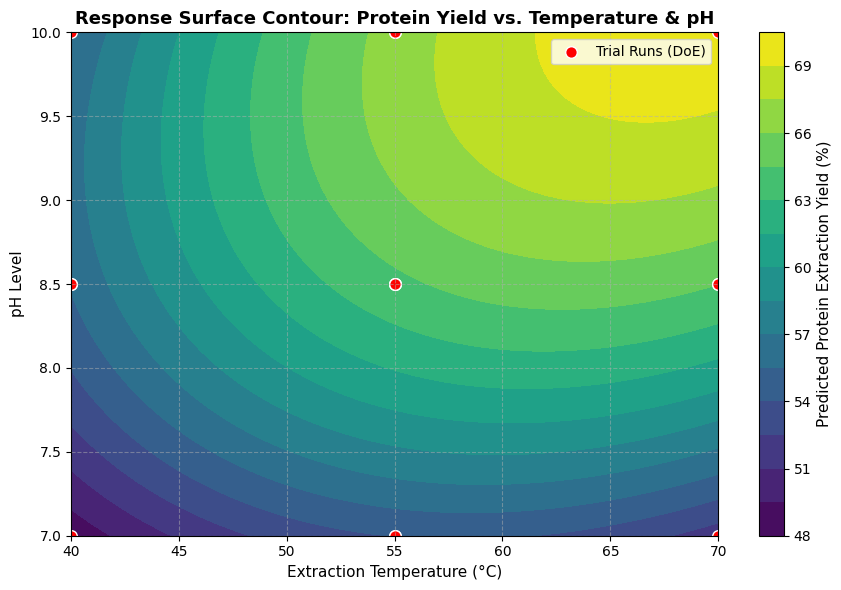

In [5]:
# =============================================================
# STEP 3: GENERATE 2D CONTOUR PLOT (Response Surface Methodology)
# =============================================================

# Create a smooth grid for Temperature (X1) and pH (X2)
# while holding Time constant at the center point (X3_coded = 0)
x1_grid = np.linspace(-1, 1, 100)
x2_grid = np.linspace(-1, 1, 100)
X1, X2 = np.meshgrid(x1_grid, x2_grid)

# Prepare grid data frame for prediction using our fitted OLS model
grid_data = pd.DataFrame({
    'X1_coded': X1.ravel(),
    'X2_coded': X2.ravel(),
    'X3_coded': 0 # Held constant at 60 mins
})

# Predict Yield values across the entire grid
Y_pred = model.predict(grid_data).values.reshape(X1.shape)

# Convert coded grid coordinates back to actual physical units
Temp_grid = X1 * 15.0 + 55.0
pH_grid   = X2 * 1.5 + 8.5

# Plotting the Contour Graph
plt.figure(figsize=(9, 6))
contour = plt.contourf(Temp_grid, pH_grid, Y_pred, levels=20, cmap='viridis')
cbar = plt.colorbar(contour)
cbar.set_label('Predicted Protein Extraction Yield (%)', fontsize=11)

# Overlay your actual experimental trial runs as red dots
plt.scatter(df['Temperature_C'], df['pH_Level'], color='red', edgecolor='white', s=70, label='Trial Runs (DoE)')

plt.title('Response Surface Contour: Protein Yield vs. Temperature & pH', fontsize=13, fontweight='bold')
plt.xlabel('Extraction Temperature (°C)', fontsize=11)
plt.ylabel('pH Level', fontsize=11)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()